# Linear clock missingness benchmark

Replicates the experiments from notebooks 03 and 04 on the **published linear regression clocks** (Horvath, Hannum, PhenoAge, GrimAge V2) rather than EpiHydra.

The held-out data is the same GEO test set never seen during EpiHydra training, so comparisons between this notebook and notebooks 03/04 are on the same samples.

Missingness is injected by setting CpG rows to `NaN` in the beta matrix before prediction. The clocks handle missing probes via built-in imputation (`impute_beta=0.5`).

**Key design choice:** all missingness metrics compare the masked prediction against the **zero-masking (baseline) prediction for the same sample**, not against chronological age. This isolates the degradation caused by missingness from each clock's inherent bias or offset relative to chronological age -- PhenoAge, for example, is designed to predict phenotypic rather than chronological age, so its MAE vs. chron age reflects its design intent, not its quality under missingness.

Requires `epigenetic_clocks.py` on the Python path.

## Parameters
Set everything here, then run all cells.

In [1]:
from pathlib import Path
import numpy as np
import gc

ROOT = Path("/work/gr-fe/bryan/EpiHydra")

# ── Held-out datasets (never seen during EpiHydra training) ───────
DATASET_IDS = ["GSE27097", "GSE40279", "GSE41037", "GSE42861"]
DATA_ROOT   = ROOT / "data/02_processed"

# ── Clock coefficient files ───────────────────────────────────────
COEF_ROOT    = ROOT / "data/03_final"
HORVATH_CSV  = COEF_ROOT / "Horvath/horvath.csv"
#HANNUM_CSV   = COEF_ROOT / "Hannum/hannum.csv"
PHENOAGE_CSV = COEF_ROOT / "PhenoAge/phenoage.csv"
#GRIMAGE_CSV  = COEF_ROOT / "GrimAge/GrimAgeV2.csv"

# Hannum intercept -- supply the correct value from the paper supplementary
HANNUM_INTERCEPT = 0.0   # update this

# ── Output ────────────────────────────────────────────────────────
SAVE_DIR = ROOT / "results/linear_clocks/missingness"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── Analysis 1: synthetic random masking ──────────────────────────
# Same levels as notebooks 03/04 for direct comparison
MASK_FRACTIONS = np.round(np.arange(0.0, 1.0, 0.1), 2).tolist()
MASK_SEED      = 43

# ── Analysis 2: real coverage bins ───────────────────────────────
N_COVERAGE_BINS = 5
MIN_BIN_SAMPLES = 3

# ── Analysis 3: systematic probe removal ─────────────────────────
# "high_variance"   = most informative probes first
# "low_variance" = least informative probes first
# "mean"       = most extreme methylation first

REMOVAL_STRATEGY  = "high_variance"
REMOVAL_FRACTIONS = MASK_FRACTIONS

## Imports

In [2]:
import pickle
import warnings
import sys

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from sklearn.metrics import r2_score

%matplotlib inline

from methylgpt import MethylGPTModel, MethylVocab
from scgpt.tokenizer import tokenize_and_pad_batch, random_mask_value
from evaluation import eval_utils as eu 
sys.path.insert(0 , '../02_epiclocks/')
from clocks.epigenetic_clocks import (
    Horvath, Hannum, PhenoAge,
    GrimAgeV2, GrimAgeAdapter,
    run_all_clocks,
)

print("Imports OK")

Imports OK


## Helper functions

These parallel the `eval_utils` equivalents (which operate on tokenised batches)
but work directly on beta-value DataFrames.

In [3]:
def _run_and_collect_raw(masked_datasets, clocks, chron_ages, clock_names, save_dir):
    """Run all clocks; return per-sample predictions as {clock: Series(id->pred)}."""
    raw_all = run_all_clocks(
        datasets       = masked_datasets,
        save_path      = save_dir,
        clocks         = clocks,
        chron_ages     = chron_ages,
        impute_missing = False,
        save_summary   = False,
        verbose        = False,
    )
    # Concatenate across datasets into one Series per clock
    result = {}
    for name in clock_names:
        parts = [age_df[name].dropna() for age_df in raw_all.values()]
        result[name] = pd.concat(parts)
    return result


def _compare_to_baseline(masked_datasets, baseline_preds, clocks, chron_ages,
                          clock_names, save_dir):
    """
    Run all clocks on masked_datasets and score each prediction against the
    BASELINE prediction (zero masking) for the same sample, not against
    chronological age.

    This isolates the effect of missingness from each clock's inherent
    bias or offset relative to chronological age.

    Returns pooled (preds, baseline_refs) per clock across all datasets,
    aligned on sample ID so only samples present in both are included.
    """
    masked_preds = _run_and_collect_raw(
        masked_datasets, clocks, chron_ages, clock_names, save_dir
    )
    preds        = {name: [] for name in clock_names}
    baseline_refs = {name: [] for name in clock_names}
    for name in clock_names:
        # Align on sample ID -- only score samples present in both
        common = masked_preds[name].index.intersection(baseline_preds[name].index)
        preds[name]         = masked_preds[name].loc[common].values
        baseline_refs[name] = baseline_preds[name].loc[common].values
    return (
        {n: np.array(v) for n, v in preds.items()},
        {n: np.array(v) for n, v in baseline_refs.items()},
    )


def get_clock_probes(clocks):
    # Known synthetic/covariate labels that are not methylation probes
    NON_PROBE_LABELS = {
        "Intercept", "Age", "Female", "Male",
        "__hannum_intercept__",  # Hannum synthetic label (safety)
    }
    
    clock_probes = {}
    for name, clock in clocks.items():
        coef = clock.coefficients
        cpg_col = getattr(clock, 'CPG_COL', 'CpG')
        probes = set(
            p for p in coef[cpg_col]
            if p not in NON_PROBE_LABELS
        )
        clock_probes[name] = probes
    return clock_probes

def mask_random_cpgs(dataset, clock_probes, mask_frac, rng):
    """
    For each clock, mask a random fraction of its own observed probes.
    Dataset is filtered to each clock's probes only before copying.
    
    Returns
    -------
    per_clock_masked : dict[str, dict[str, pd.DataFrame]]
        {clock_name: {gse: masked_beta_matrix}}
    """
    if mask_frac == 0.0:
        return {
            clock_name: {
                gse: cpg_df.loc[cpg_df.index.intersection(probes)]
                for gse, cpg_df in dataset.items()
            }
            for clock_name, probes in clock_probes.items()
        }

    observed_in_dataset = {
        gse: set(cpg_df.index[cpg_df.notna().any(axis=1)].tolist())
        for gse, cpg_df in dataset.items()
    }

    per_clock_masked = {}

    for clock_name, probes in clock_probes.items():
        masked = {}
        for gse, cpg_df in dataset.items():
            # Filter to this clock's probes only
            clock_rows = cpg_df.index.intersection(probes)
            df = cpg_df.loc[clock_rows].copy()

            # Mask a random fraction of observed eligible probes
            eligible  = list(probes & observed_in_dataset[gse])
            n_remove  = max(1, int(len(eligible) * mask_frac))
            to_remove = rng.choice(eligible, size=n_remove, replace=False)
            df.loc[df.index.intersection(to_remove)] = np.nan

            masked[gse] = df.dropna(how='all')

        per_clock_masked[clock_name] = masked

    return per_clock_masked

def mask_systematic_cpgs(dataset, clock_ranked_probes, clock_probes, frac):
    """
    Returns a dict of {clock_name: masked_dataset} where each clock
    has had frac of its own ranked probes removed. Dataset is filtered
    to each clock's probes only before copying, mirroring mask_random_cpgs.

    clock_ranked_probes : {clock_name: [ordered list of probe IDs]}
    clock_probes        : {clock_name: set of probe IDs}
    """
    per_clock_masked = {}

    for clock_name, ranked_probes in clock_ranked_probes.items():
        n_remove   = int(frac * len(ranked_probes))
        probes_off = set(ranked_probes[:n_remove])

        masked = {}
        for gse, cpg_df in dataset.items():
            # Filter to this clock's probes only, dropping all-NaN rows
            clock_rows = cpg_df.index.intersection(clock_probes[clock_name])
            df = cpg_df.loc[clock_rows].dropna(how="all").copy()

            # Mask the probes to remove
            to_mask = df.index.intersection(probes_off)
            if len(to_mask):
                df.loc[to_mask] = np.nan

            masked[gse] = df

        per_clock_masked[clock_name] = masked

    return per_clock_masked

def rank_cpgs_linear(dataset, clock_probes, strategy="low_variance"):
    """
    Rank CpG probes for systematic removal, separately for each clock.

    Ranking is restricted to the probes each clock actually uses,
    intersected with what is observed (non-all-NaN) in the data.
    This ensures removal_frac refers to the fraction of clock-relevant
    probes removed, not all array probes.

    Parameters
    ----------
    dataset : dict[str, pd.DataFrame]
        {gse: beta_matrix (n_CpGs x n_samples)}
    clock_probes : dict[str, set]
        {clock_name: set of probe IDs} from get_clock_probes()
    strategy : str
        'low_variance'  -- remove lowest-variance probes first
        'high_variance' -- remove highest-variance probes first
        'mean'          -- remove most extreme mean methylation first

    Returns
    -------
    ranked : dict[str, list]
        {clock_name: ordered list of probe IDs to remove}
    label : str
        Human-readable description of the strategy used.
    """
    strategy_labels = {
        "low_variance"  : "ascending variance (least variable first)",
        "high_variance" : "descending variance (most variable first)",
        "mean"          : "descending mean absolute value (most extreme first)",
    }
    if strategy not in strategy_labels:
        raise ValueError(f"strategy must be one of {list(strategy_labels)}; got '{strategy}'")

    label = strategy_labels[strategy]

    # Probes present and not entirely NaN in at least one dataset
    observed_probes = set()
    for cpg_df in dataset.values():
        observed_probes.update(
            cpg_df.index[cpg_df.notna().any(axis=1)].tolist()
        )

    ranked = {}

    for clock_name, probes in clock_probes.items():
        # Restrict to probes this clock uses that are actually observed
        eligible = sorted(probes & observed_probes)

        # Collect per-probe values across all datasets
        probe_vals = {p: [] for p in eligible}
        for cpg_df in dataset.values():
            present = [p for p in eligible if p in cpg_df.index]
            for probe in present:
                vals = cpg_df.loc[probe].dropna().values.astype(float)
                probe_vals[probe].extend(vals.tolist())

        scores = {}
        for probe, vals in probe_vals.items():
            v = np.array(vals)
            v = v[np.isfinite(v)]
            if len(v) == 0:
                scores[probe] = np.nan
            elif strategy == "mean":
                scores[probe] = float(np.mean(np.abs(v)))
            else:  # low_variance or high_variance
                scores[probe] = float(np.var(v))

        s = pd.Series(scores).dropna()

        ascending = strategy == "low_variance"
        ranked_probes = s.sort_values(ascending=ascending).index.tolist()

        # Append any probes with no observed values last
        unobserved = [p for p in eligible if p not in s.index]
        ranked[clock_name] = ranked_probes + unobserved

        print(f"  {clock_name}: {len(ranked[clock_name]):,} eligible probes "
              f"({len(unobserved)} unobserved, ranked last)")

    return ranked, label
    
def metrics_from_arrays(p, t):
    """Return (mae, pearson_r, r2). Returns NaN tuple if fewer than 2 samples."""
    n = len(p)
    if n < 2:
        return np.nan, np.nan, np.nan
    mae = float(np.mean(np.abs(p - t)))
    r   = float(pearsonr(p, t)[0]) if np.std(p) > 0 and np.std(t) > 0 else np.nan
    r2  = float(r2_score(t, p))    if np.std(p) > 0 else np.nan
    return mae, r, r2

## Load held-out datasets

Each GEO series is loaded from its own `methylation.pkl`. The CpG matrix is shaped
`(n_CpGs x n_samples)` with probe IDs as the index.

Completely NaN probes (never observed in any sample) are dropped; they carry no
information and would inflate apparent coverage.

In [4]:
dataset    = {}
chron_ages = {}
female     = {}

for gse in DATASET_IDS:
    with open(DATA_ROOT / gse / "methylation.pkl", "rb") as f:
        methylation = pickle.load(f)

    # Drop probes that are entirely unobserved across all samples
    cpg = methylation["CpG"].dropna(how="all")

    dataset[gse]    = cpg
    chron_ages[gse] = methylation["meta"].set_index("ID")["age"]
    female[gse]     = methylation["meta"].set_index("ID")["gender"] == "female"

    n_cpg, n_samp = cpg.shape
    lo, hi        = chron_ages[gse].min(), chron_ages[gse].max()
    pct_missing   = cpg.isna().values.mean() * 100
    print(f"{gse}: {n_samp} samples | {n_cpg:,} CpGs | "
          f"age {lo:.1f}-{hi:.1f} yrs | {pct_missing:.1f}% NaN")
    
    # Free the raw pickle immediately after extracting what we need
    del methylation, cpg

GSE27097: 494 samples | 27,578 CpGs | age 3.6-17.8 yrs | 0.0% NaN
GSE40279: 656 samples | 473,034 CpGs | age 19.0-101.0 yrs | 0.0% NaN
GSE41037: 720 samples | 27,578 CpGs | age 16.0-88.0 yrs | 0.0% NaN
GSE42861: 689 samples | 485,577 CpGs | age 18.0-70.0 yrs | 0.0% NaN


## Instantiate clocks

`GrimAgeAdapter` captures the per-dataset age and sex arrays so `run_all_clocks`
can call every clock with the same `predict(methylation, impute_missing, verbose)` signature.

In [7]:
horvath  = Horvath(coefficients_path=HORVATH_CSV)
hannum   = Hannum(coefficients_path=HANNUM_CSV, intercept=HANNUM_INTERCEPT)
phenoage = PhenoAge(coefficients_path=PHENOAGE_CSV)
# grimage  = GrimAgeAdapter(
#     GrimAgeV2(coefficients_path=GRIMAGE_CSV),
#     chron_ages = chron_ages,
#     female     = female,
# )

# Keyed dict so column names are explicit and consistent with notebooks 03/04
clocks = {
    "horvath_age"  : horvath,
    "hannum_age"   : hannum,
    "phenoage_age" : phenoage,
    #"grimage_age"  : grimage,
}

clock_names = list(clocks.keys())
print("Clocks:", clock_names)

clock_probes = get_clock_probes(clocks)

Loaded 353 CpG coefficients + intercept.
Loaded 513 CpG coefficients + intercept.
Clocks: ['horvath_age', 'phenoage_age']


## Baseline predictions (zero masking)

Runs all clocks with no extra missingness to establish the reference predictions.
All subsequent analyses score masked predictions **against these baseline predictions**
rather than against chronological age, so we measure how much missingness degrades
each clock's own output independently of its inherent offset from chronological age.

MAE / r / R² against chronological age are also shown for context, but are not used
in the missingness analyses.

In [8]:
# baseline_preds: {clock_name: Series(sample_id -> predicted_age)}
# Stored with sample IDs so masked runs can be aligned on ID before scoring.
baseline_preds = _run_and_collect_raw(
    dataset, clocks, chron_ages, clock_names,
    save_dir = SAVE_DIR / "baseline",
)

# Report performance vs. chronological age for context only
baseline_rows = []
for name in clock_names:
    p   = baseline_preds[name]
    # Align chronological ages to prediction index
    all_chron = pd.concat([chron_ages[gse] for gse in DATASET_IDS])
    t   = all_chron.reindex(p.index).dropna()
    p_a = p.loc[t.index].values
    mae, r, r2 = metrics_from_arrays(p_a, t.values)
    baseline_rows.append({
        "clock"    : name,
        "n"        : len(p_a),
        "mae_vs_chron"      : round(mae, 3),
        "pearson_r_vs_chron": round(r, 3),
        "r2_vs_chron"       : round(r2, 3),
    })

baseline = pd.DataFrame(baseline_rows).set_index("clock")
print("Baseline clock performance vs. chronological age (context only)")
display(baseline)

Baseline clock performance vs. chronological age (context only)


,n,mae_vs_chron,pearson_r_vs_chron,r2_vs_chron
clock,,,,
horvath_age,2463,3.879,0.973,0.945
phenoage_age,2463,9.636,0.941,0.705


## Analysis 1 — Synthetic random masking

For each masking fraction, a random subset of probe rows is set to `NaN` before
prediction. The clocks impute the missing value at `beta=0.5`. The same seed is
used at every fraction so variation reflects masking level only.

Metrics are computed by comparing the **masked prediction** against the
**zero-masking (baseline) prediction for the same sample**. MAE here measures
how far the clock shifts from its own best answer, not from chronological age.

In [9]:
rand_rows = []
N_BOOTSTRAP = 10

for frac in MASK_FRACTIONS:
    # Collect per-bootstrap results before averaging
    boot_rows = {clock_name: [] for clock_name in clock_names}
    
    for boot_idx in range(N_BOOTSTRAP):
        # Derive a unique seed per bootstrap from the base seed
        rng = np.random.default_rng(MASK_SEED + boot_idx)
        per_clock_masked = mask_random_cpgs(dataset, clock_probes, frac, rng)

        for clock_name in clock_names:
            preds, refs = _compare_to_baseline(
                per_clock_masked[clock_name],
                baseline_preds,
                {clock_name: clocks[clock_name]},
                chron_ages,
                [clock_name],
                save_dir=SAVE_DIR / "masking_tmp",
            )
            p, t = preds[clock_name], refs[clock_name]
            mae, r, r2 = metrics_from_arrays(p, t)
            boot_rows[clock_name].append(dict(mae=mae, pearson_r=r, r2=r2))

    # Average across bootstraps and store
    for clock_name in clock_names:
        df_boot = pd.DataFrame(boot_rows[clock_name])
        rand_rows.append(dict(
            clock     = clock_name,
            mask_frac = frac,
            mae       = df_boot["mae"].mean(),
            pearson_r = df_boot["pearson_r"].mean(),
            r2        = df_boot["r2"].mean(),
            n_boot    = N_BOOTSTRAP,
        ))

    print(f"  frac={frac:.1f} done ({N_BOOTSTRAP} bootstraps)")

mask_results = pd.DataFrame(rand_rows)

  frac=0.0 done (10 bootstraps)
  frac=0.1 done (10 bootstraps)
  frac=0.2 done (10 bootstraps)
  frac=0.3 done (10 bootstraps)
  frac=0.4 done (10 bootstraps)
  frac=0.5 done (10 bootstraps)
  frac=0.6 done (10 bootstraps)
  frac=0.7 done (10 bootstraps)
  frac=0.8 done (10 bootstraps)
  frac=0.9 done (10 bootstraps)


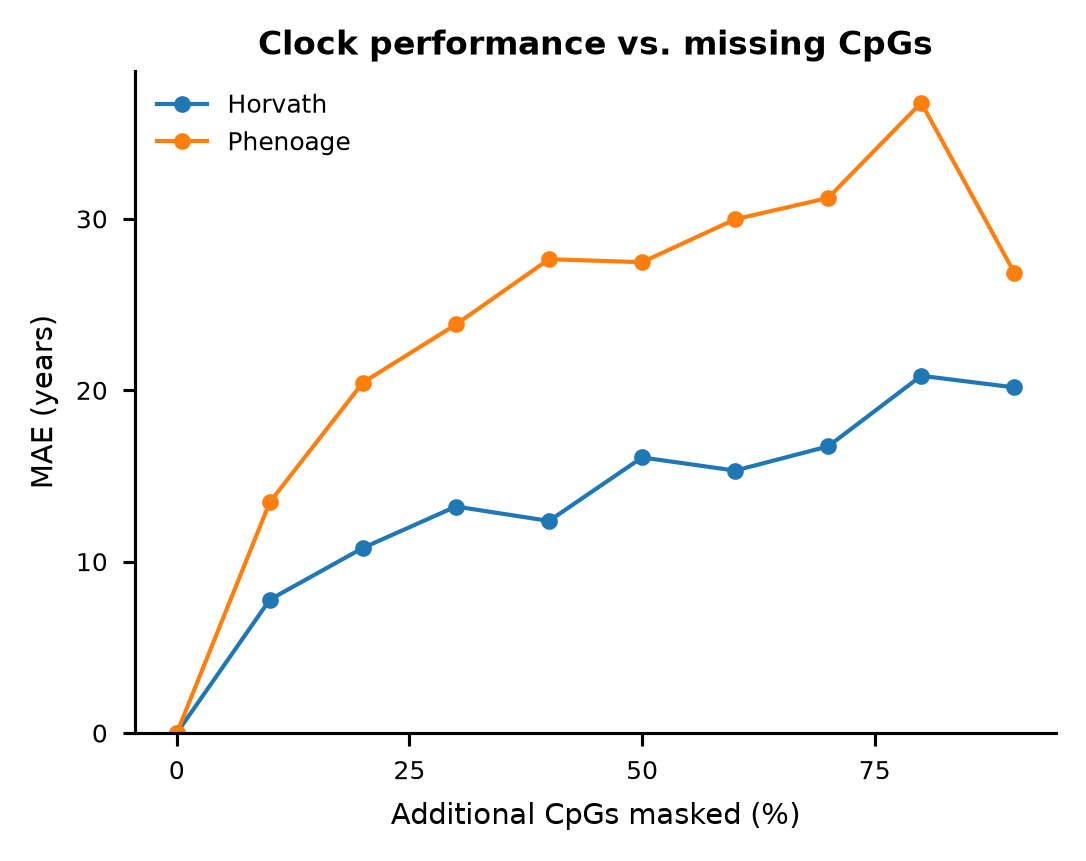

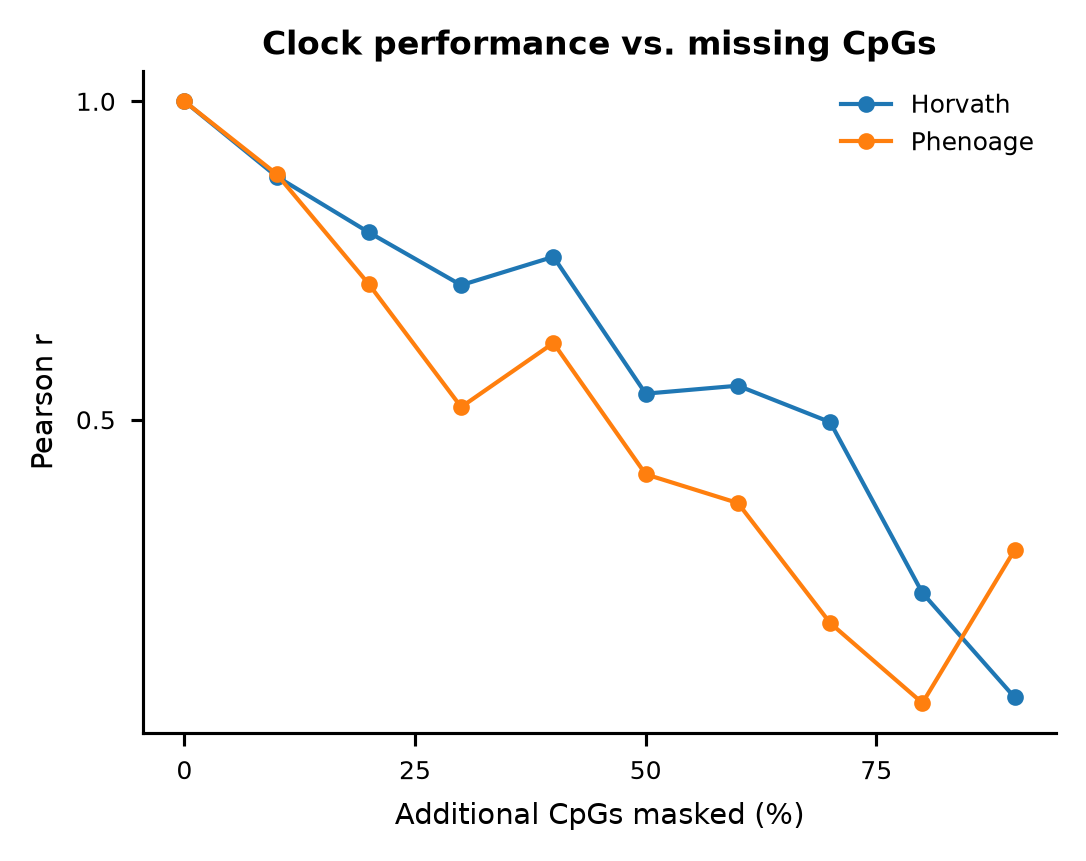

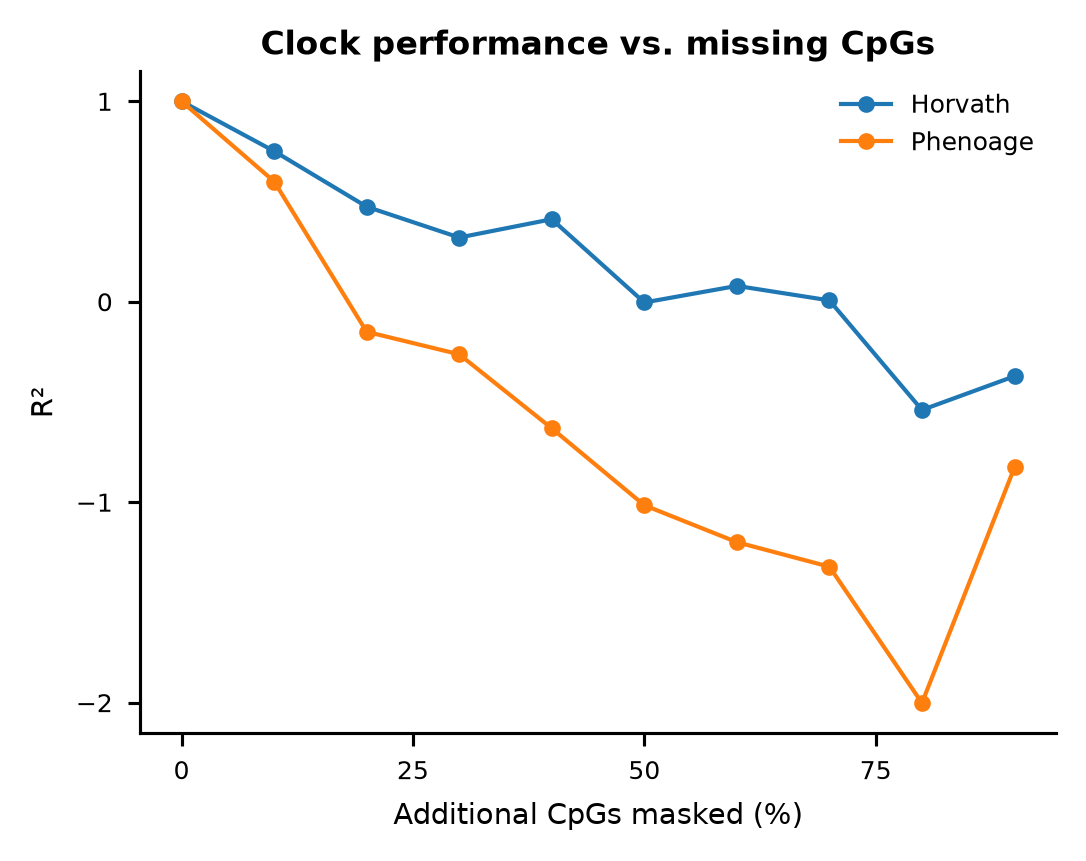

In [10]:
for metric in ("mae", "pearson_r", "r2"):
    fig, ax = eu.plot_missing_fraction_curves(mask_results, metric=metric, x='mask_frac',
                                              clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"masking_curve_{metric}.pdf")
        fig.savefig(SAVE_DIR / f"masking_curve_{metric}.png")
    plt.show()

## Analysis 2 — Real CpG coverage bins

Each sample is grouped by its actual observed CpG coverage fraction and per-clock
performance is computed within each bin.

As with Analysis 1, the reference is each sample's **baseline prediction** (zero
masking), so the metric captures how much real probe missingness shifts the clock
from its own best answer.

In [11]:
# Build per-sample coverage from the actual beta matrices
coverage_parts = []
for gse, cpg_df in dataset.items():
    cov_df = cpg_df.notna().mean(axis=0).rename("cpg_coverage").to_frame()
    cov_df.index.name = "ID"
    cov_df["dataset"]   = gse
    cov_df["chron_age"] = chron_ages[gse].reindex(cov_df.index)
    coverage_parts.append(cov_df)

coverage_df = pd.concat(coverage_parts)
print("Coverage distribution (all datasets):")
print(coverage_df["cpg_coverage"].describe().round(3))

Coverage distribution (all datasets):
count    2559.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: cpg_coverage, dtype: float64


In [12]:
# Run baseline predictions dataset-by-dataset to keep sample IDs for the join
pred_frames = []
for gse, cpg_df in dataset.items():
    raw = run_all_clocks(
        datasets       = {gse: cpg_df},
        save_path      = SAVE_DIR / "coverage_tmp",
        clocks         = clocks,
        chron_ages     = chron_ages,
        impute_missing = True,
        save_summary   = False,
        verbose        = False,
    )[gse]
    raw["dataset"] = gse
    pred_frames.append(raw)

all_preds_df = pd.concat(pred_frames)

# _true = baseline prediction for the same sample (not chronological age)
predictions_cov = pd.DataFrame(index=all_preds_df.index)
predictions_cov["dataset"] = all_preds_df["dataset"]
for name in clock_names:
    predictions_cov[name + "_pred"] = all_preds_df[name]
    predictions_cov[name + "_true"] = baseline_preds[name].reindex(all_preds_df.index)

In [13]:
coverage_results = eu.coverage_performance(
    predictions_cov, coverage_df["cpg_coverage"], clock_names,
    n_bins      = N_COVERAGE_BINS,
    min_samples = MIN_BIN_SAMPLES,
)
display(coverage_results.round(3))

,clock,coverage_bin,coverage_mid,n,mae,pearson_r,r2
0,horvath_age,80%–100%,0.9,2559,0.0,1.0,1.0
1,phenoage_age,80%–100%,0.9,2559,0.0,1.0,1.0


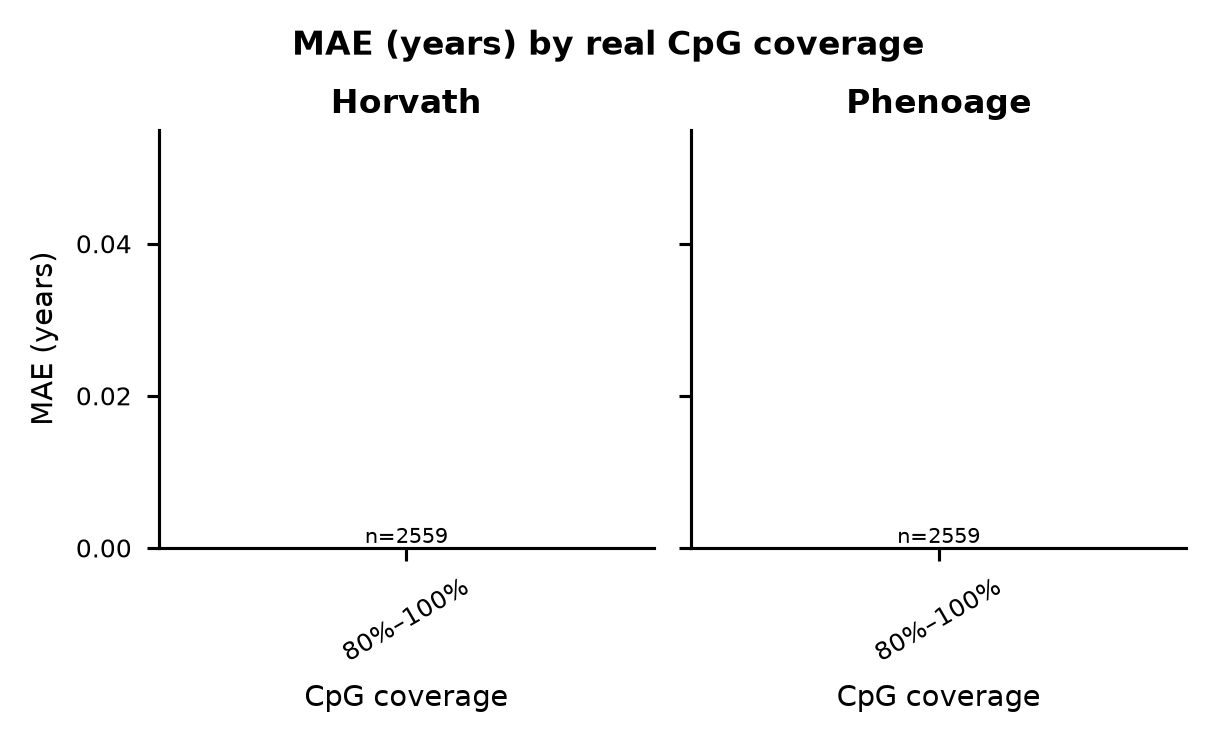

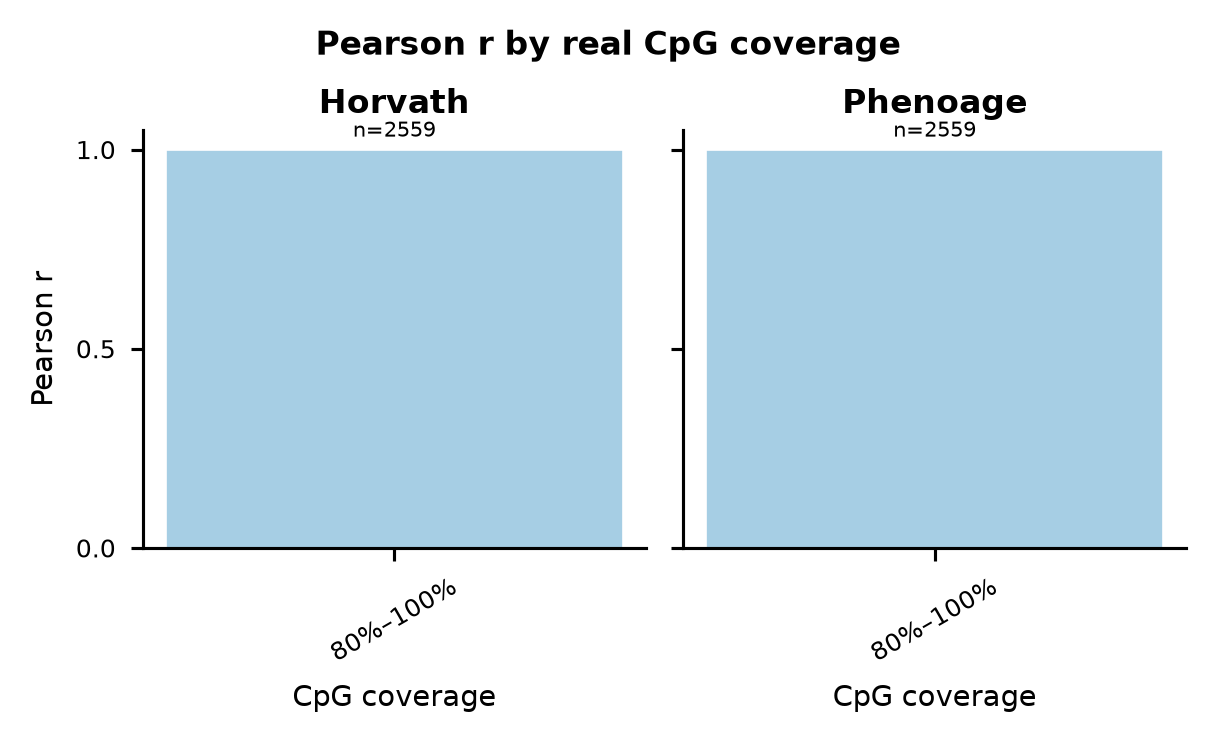

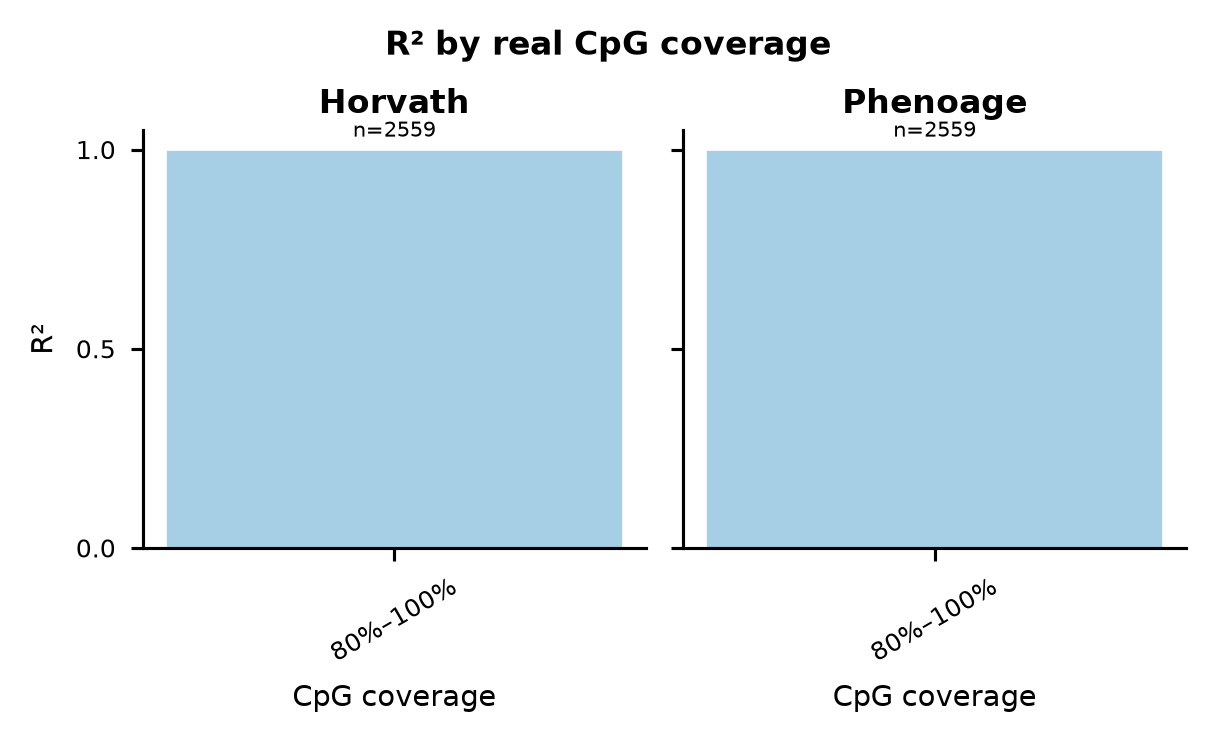

In [14]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_coverage_performance(coverage_results, metric=metric,
                                             clock_names=clock_names)
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"coverage_bins_{metric}.pdf")
        fig.savefig(SAVE_DIR / f"coverage_bins_{metric}.png")
    plt.show()

## Analysis 3 — Systematic probe removal

Removes the same CpGs from every sample simultaneously, ordered by `REMOVAL_STRATEGY`.
Simulates a whole-assay failure.

As with Analyses 1 and 2, masked predictions are scored against the **baseline
prediction for the same sample**, not against chronological age.

In [15]:
ranked_probes, strategy_label = rank_cpgs_linear(dataset, strategy=REMOVAL_STRATEGY, clock_probes=clock_probes)
n_total_probes = len(ranked_probes)
print(f"Strategy  : {strategy_label}")
print(f"Total CpGs: {n_total_probes:,}")
print(f"First 5 to remove for {clock_names[0]}: {ranked_probes[clock_names[0]][:5]}")

  horvath_age: 353 eligible probes (0 unobserved, ranked last)
  phenoage_age: 513 eligible probes (0 unobserved, ranked last)
Strategy  : descending variance (most variable first)
Total CpGs: 2
First 5 to remove for horvath_age: ['cg06952310', 'cg03270204', 'cg17099569', 'cg19692710', 'cg05921699']


In [16]:
ranked_probes, strategy_label = rank_cpgs_linear(
    dataset, clock_probes, strategy=REMOVAL_STRATEGY
)

syst_rows = []

for frac in REMOVAL_FRACTIONS:
    per_clock_masked = mask_systematic_cpgs(
        dataset, ranked_probes, clock_probes, frac
    )

    for clock_name in clock_names:
        preds, refs = _compare_to_baseline(
            per_clock_masked[clock_name],
            baseline_preds,
            {clock_name: clocks[clock_name]},
            chron_ages,
            [clock_name],
            save_dir=SAVE_DIR / "removal_tmp",
        )
        p, t = preds[clock_name], refs[clock_name]
        mae, r, r2 = metrics_from_arrays(p, t)
        n_remove = int(frac * len(ranked_probes[clock_name]))
        syst_rows.append(dict(clock=clock_name, removal_frac=frac,
                              n_removed=n_remove, mae=mae,
                              pearson_r=r, r2=r2, n=len(p)))

    print(f"  frac={frac:.1f} done")

systematic_results = pd.DataFrame(syst_rows)

  horvath_age: 353 eligible probes (0 unobserved, ranked last)
  phenoage_age: 513 eligible probes (0 unobserved, ranked last)
  frac=0.0 done
  frac=0.1 done
  frac=0.2 done
  frac=0.3 done
  frac=0.4 done
  frac=0.5 done
  frac=0.6 done
  frac=0.7 done
  frac=0.8 done
  frac=0.9 done


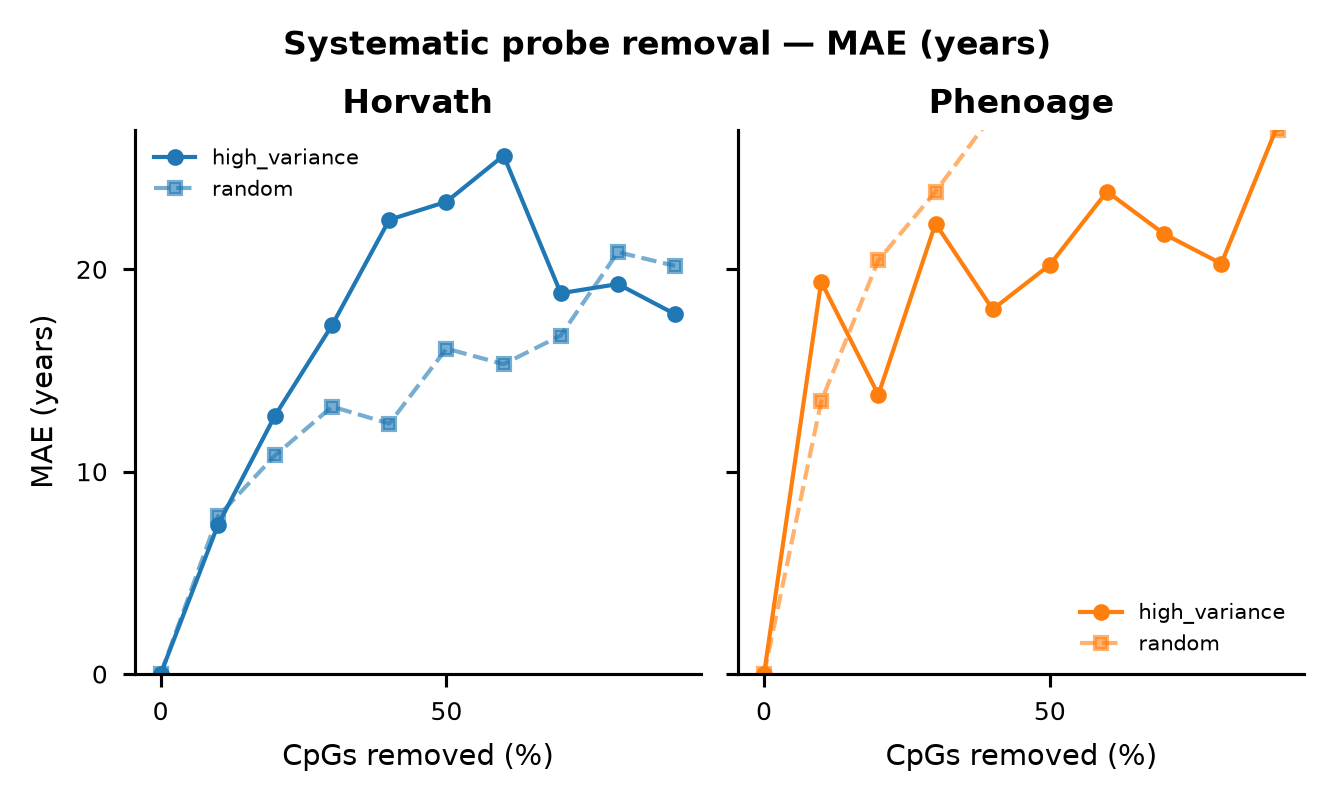

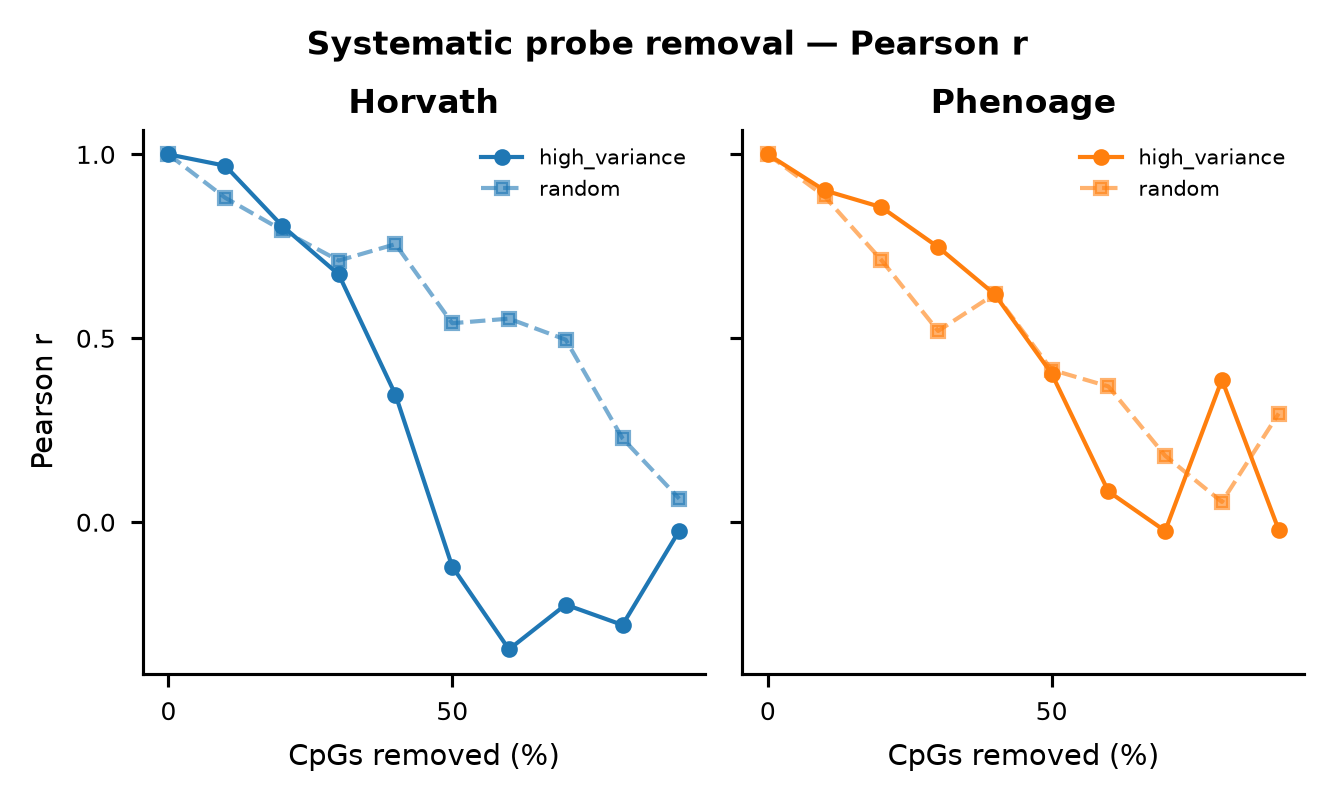

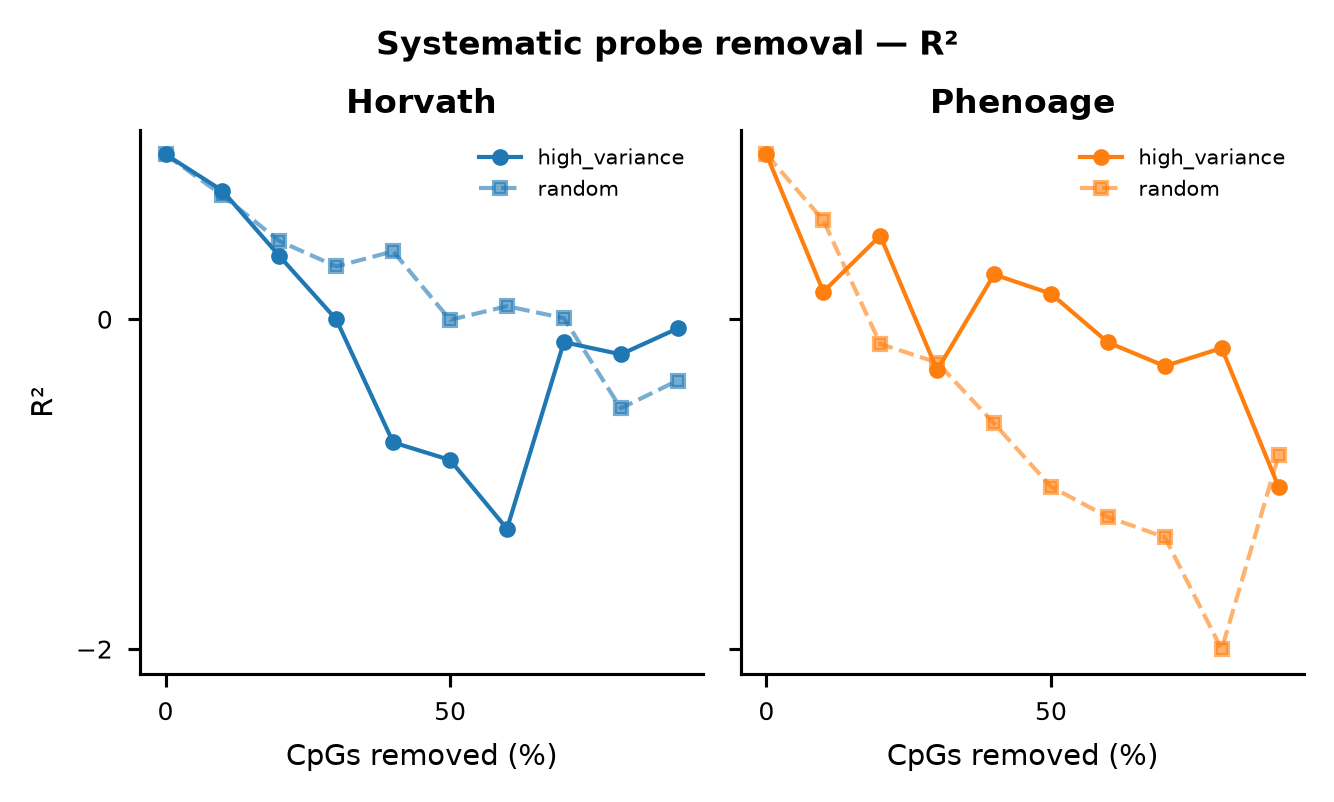

In [25]:
for metric in ("mae", "pearson_r", "r2"):
    fig, axes = eu.plot_systematic_removal_curves(
        systematic_results,
        random_results = mask_results.rename(columns={'mask_frac' : 'removal_frac'}),   # dashed overlay from Analysis 1
        metric         = metric,
        clock_names    = clock_names,
        strategy_label = REMOVAL_STRATEGY,
        x = 'removal_frac'
    )
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"systematic_removal_{metric}.pdf")
        fig.savefig(SAVE_DIR / f"systematic_removal_{metric}.png")
    plt.show()

## Removal strategy comparison

All three strategies overlaid per clock. For linear clocks this directly reveals
whether the elastic-net weights concentrate on high-variance probes: if `variance`
and `sequential` produce the same MAE curve, coefficient magnitude matters more
than probe variability.

  horvath_age: 353 eligible probes (0 unobserved, ranked last)
  phenoage_age: 513 eligible probes (0 unobserved, ranked last)
  low_variance done
  horvath_age: 353 eligible probes (0 unobserved, ranked last)
  phenoage_age: 513 eligible probes (0 unobserved, ranked last)
  high_variance done
  horvath_age: 353 eligible probes (0 unobserved, ranked last)
  phenoage_age: 513 eligible probes (0 unobserved, ranked last)
  mean done


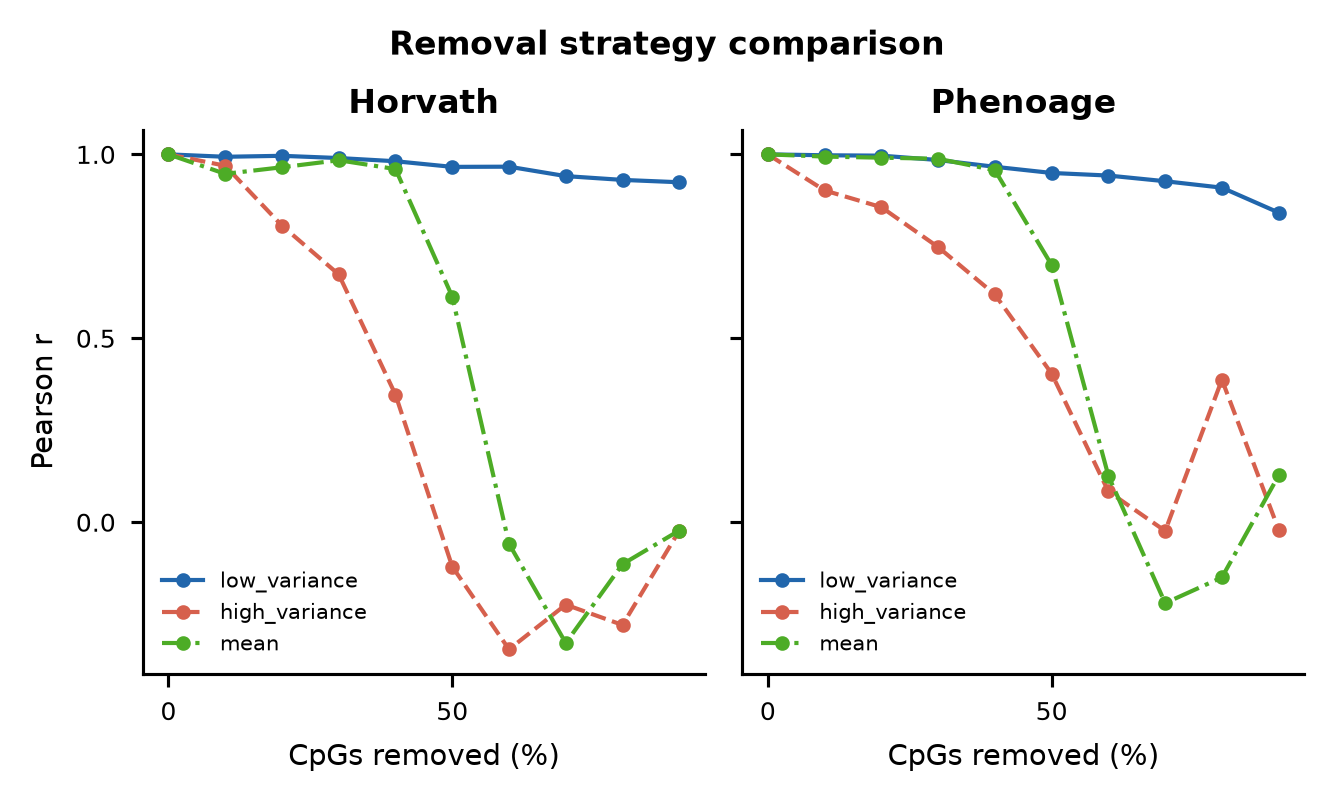

In [26]:
COMPARE_METRIC = "pearson_r"
strategy_dfs   = {}

for strat in ("low_variance", "high_variance", "mean"):
    ranked, r_label = rank_cpgs_linear(dataset, clock_probes, strategy=strat)
    rows = []
    for frac in REMOVAL_FRACTIONS:
        per_clock_masked = mask_systematic_cpgs(dataset, ranked, clock_probes, frac)

        for clock_name in clock_names:
            preds, refs = _compare_to_baseline(
                per_clock_masked[clock_name],
                baseline_preds,
                {clock_name: clocks[clock_name]},
                chron_ages,
                [clock_name],
                save_dir=SAVE_DIR / "strat_tmp",
            )
            p, t = preds[clock_name], refs[clock_name]
            mae, r, r2 = metrics_from_arrays(p, t)
            n_remove = int(frac * len(ranked[clock_name]))
            rows.append(dict(clock=clock_name, removal_frac=frac,
                             n_removed=n_remove, mae=mae,
                             pearson_r=r, r2=r2, n=len(p)))

    strategy_dfs[strat] = (pd.DataFrame(rows), r_label)
    print(f"  {strat} done")

colors  = {"low_variance": "#2166AC", "high_variance": "#D6604D", "mean": "#4DAC26"}
linesty = {"low_variance": "-",       "high_variance": "--",      "mean": "-."}

with plt.rc_context(eu._NM_RC):
    n_c   = len(clock_names)
    fig_w = min(183, 55 * n_c) / 25.4
    fig, axes = plt.subplots(1, n_c, figsize=(fig_w, 65 / 25.4),
                             sharey=True, constrained_layout=True)
    if n_c == 1:
        axes = [axes]

    for ax, name in zip(axes, clock_names):
        for strat, (df, _) in strategy_dfs.items():
            sub = df[df["clock"] == name].sort_values("removal_frac")
            ax.plot(sub["removal_frac"] * 100, sub[COMPARE_METRIC],
                    color=colors[strat], ls=linesty[strat], lw=1.0,
                    marker="o", markersize=2.5, label=strat)
        ax.set_title(eu._clean(name), pad=4, fontweight="bold")
        ax.set_xlabel("CpGs removed (%)")
        ax.legend(frameon=False, fontsize=5)

    ylabel = {"mae": "MAE (years)", "pearson_r": "Pearson r", "r2": "R²"}[COMPARE_METRIC]
    axes[0].set_ylabel(ylabel)
    fig.suptitle("Removal strategy comparison", fontsize=8, fontweight="bold")

if SAVE_DIR:
    fig.savefig(SAVE_DIR / f"strategy_comparison_{COMPARE_METRIC}.pdf")
plt.show()

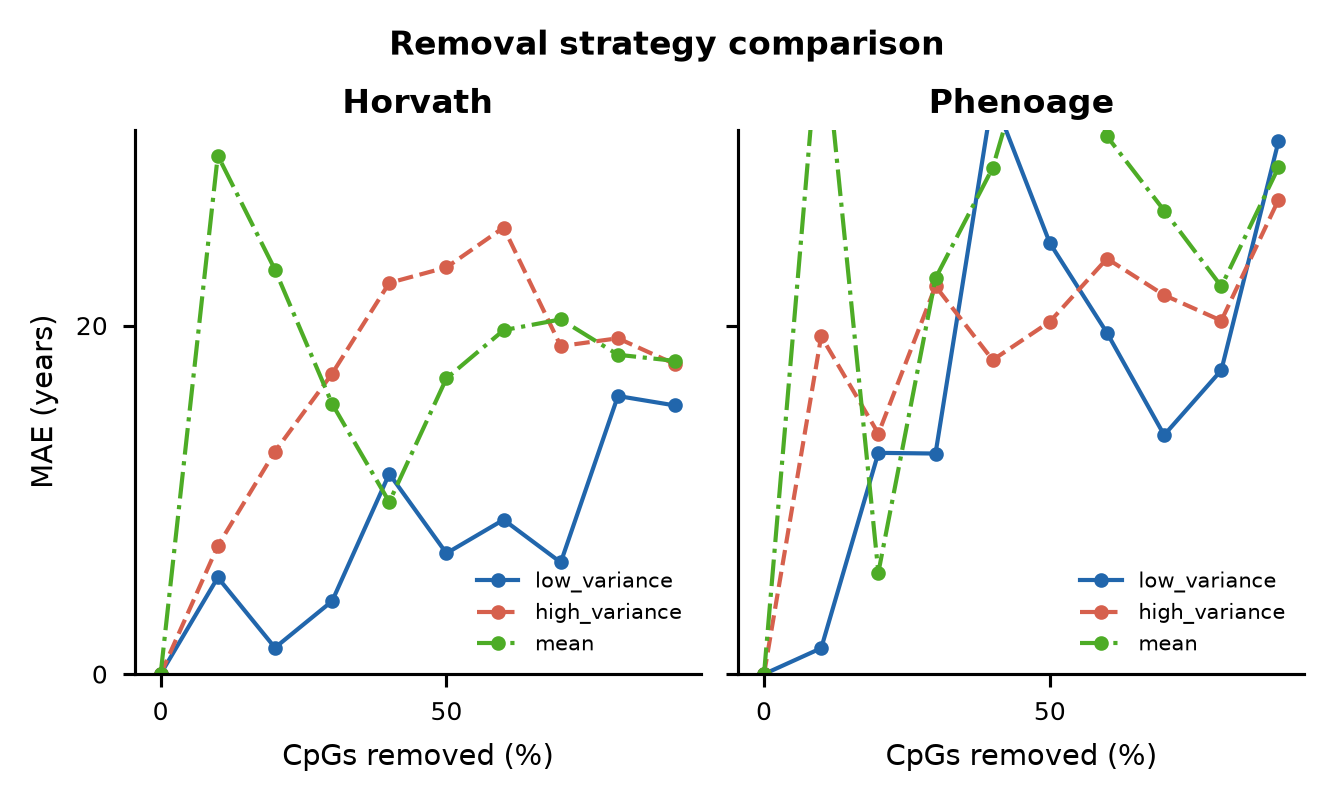

In [27]:
COMPARE_METRIC = "mae"
colors  = {"low_variance": "#2166AC", "high_variance": "#D6604D", "mean": "#4DAC26"}
linesty = {"low_variance": "-",       "high_variance": "--",      "mean": "-."}

with plt.rc_context(eu._NM_RC):
    n_c   = len(clock_names)
    fig_w = min(183, 55 * n_c) / 25.4
    fig, axes = plt.subplots(1, n_c, figsize=(fig_w, 65 / 25.4),
                             sharey=True, constrained_layout=True)
    if n_c == 1:
        axes = [axes]

    for ax, name in zip(axes, clock_names):
        for strat, (df, _) in strategy_dfs.items():
            sub = df[df["clock"] == name].sort_values("removal_frac")
            ax.plot(sub["removal_frac"] * 100, sub[COMPARE_METRIC],
                    color=colors[strat], ls=linesty[strat], lw=1.0,
                    marker="o", markersize=2.5, label=strat)
        ax.set_title(eu._clean(name), pad=4, fontweight="bold")
        ax.set_xlabel("CpGs removed (%)")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, fontsize=5)

    ylabel = {"mae": "MAE (years)", "pearson_r": "Pearson r", "r2": "R2"}[COMPARE_METRIC]
    axes[0].set_ylabel(ylabel)
    fig.suptitle("Removal strategy comparison", fontsize=8, fontweight="bold")

if SAVE_DIR:
    fig.savefig(SAVE_DIR / f"strategy_comparison_{COMPARE_METRIC}.pdf")
plt.show()

## Summary: degradation from worst missingness

Compares zero-masking baseline to the heaviest masking/removal level for both
analyses. All metrics are **masked prediction vs. baseline prediction**, so a
positive `delta_mae` means the clock shifted further from its own zero-masking
answer, regardless of how close that answer is to chronological age.

In [29]:
worst_frac = max(MASK_FRACTIONS)

# Baseline here is 0% masking scored against itself -- should be ~0 MAE, r~1
zero_row = mask_results[mask_results["mask_frac"] == 0.0].set_index("clock")
worst_rand = mask_results[mask_results["mask_frac"] == worst_frac].set_index("clock")
worst_syst = systematic_results[systematic_results["removal_frac"] == worst_frac].set_index("clock")

summary = zero_row[["mae", "pearson_r", "r2"]].copy()
summary.columns = [f"zero_mask_{c}" for c in summary.columns]
for metric in ("mae", "pearson_r", "r2"):
    summary[f"rand_{metric}"]       = worst_rand[metric]
    summary[f"syst_{metric}"]       = worst_syst[metric]
    summary[f"delta_rand_{metric}"] = (
        summary[f"rand_{metric}"] - summary[f"zero_mask_{metric}"]
    ).round(3)
    summary[f"delta_syst_{metric}"] = (
        summary[f"syst_{metric}"] - summary[f"zero_mask_{metric}"]
    ).round(3)

print(f"Worst fraction: {worst_frac:.0%} | Removal strategy: {REMOVAL_STRATEGY}")
print("All metrics: masked prediction vs. zero-masking baseline prediction")
display(summary.round(3))

Worst fraction: 90% | Removal strategy: high_variance
All metrics: masked prediction vs. zero-masking baseline prediction


,zero_mask_mae,zero_mask_pearson_r,zero_mask_r2,rand_mae,syst_mae,delta_rand_mae,delta_syst_mae,rand_pearson_r,syst_pearson_r,delta_rand_pearson_r,delta_syst_pearson_r,rand_r2,syst_r2,delta_rand_r2,delta_syst_r2
clock,,,,,,,,,,,,,,,
horvath_age,0.0,1.0,1.0,19.360,17.784,19.360,17.784,0.002,-0.023,-0.998,-1.023,-0.253,-0.056,-1.253,-1.056
hannum_age,0.0,1.0,1.0,30.008,25.115,30.008,25.115,0.622,0.977,-0.378,-0.023,-0.174,0.261,-1.174,-0.739
phenoage_age,0.0,1.0,1.0,23.941,27.217,23.941,27.217,0.239,-0.020,-0.761,-1.020,-0.496,-1.017,-1.496,-2.017
grimage_age,0.0,1.0,1.0,15.647,13.813,15.647,13.813,0.794,0.912,-0.206,-0.088,0.478,0.514,-0.522,-0.486
